In [4]:
import seaborn as sns
import pandas as pd
import numpy as np
from importlib import reload
import matplotlib.pyplot as plt
import polars as pl
import os
import pyvista as pv

from shapespace import ShapeSpace
import main as main
import figures as figures

In [5]:
ID_NAME = 'Nuclear_ID'
from scipy import stats
NUM_PCS = 6

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_differences(red_pc, green_pc, cohens_d, indx, dir, save_plot=False, is_somites=False):
    red = '#FF00FF'
    green = '#00ff00'
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    # 1. Density plot 
    axes[0].hist(green_pc, bins=100, alpha=0.5, color=green, label='S/G2', density=True)
    axes[0].hist(red_pc, bins=100, alpha=0.5, color=red, label='G1', density=True)
    
    axes[0].axvline(green_pc.mean(), color=green, linestyle='--', linewidth=1)
    axes[0].axvline(red_pc.mean(), color=red, linestyle='--', linewidth=1)
    axes[0].set_xlabel(f'')
    axes[0].set_ylabel('Density')
    axes[0].set_title(f'PC {indx} (Cohen\'s d = {abs(cohens_d):.3f})')

    # 2. CDF
    red_sorted = np.sort(red_pc)
    green_sorted = np.sort(green_pc)
    red_cdf = np.arange(1, len(red_sorted)+1) / len(red_sorted)
    green_cdf = np.arange(1, len(green_sorted)+1) / len(green_sorted)

    axes[1].plot(green_sorted, green_cdf, color=green, label='S/G2', alpha=0.7)
    axes[1].plot(red_sorted, red_cdf, color=red, label='G1', alpha=0.7)

    axes[1].set_xlabel(f'')
    axes[1].set_xlim()
    axes[1].set_ylabel('Cumulative Probability')
    axes[1].set_title('CDF')
    axes[1].legend(loc='best')
    axes[1].grid(alpha=0.3)
    if save_plot:
        plot_name = f'PC{indx}_fucci_distribution' if not is_somites else f'PC{indx}_distribution_somites'
        figures.save_vectorized(dir=dir,
                        fig=fig,
                        plot_name=plot_name)
    return fig
    
def plot_differences_somites(pc1, pc2, cohens_d, indx, dir, label1, label2, save_plot=True):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    # 1. Density plot 
    axes[0].hist(pc1, bins=100, alpha=0.5, color='darkorange', label=label1, density=True)
    axes[0].hist(pc2, bins=100, alpha=0.5, color='blue', label=label2, density=True)
    axes[0].axvline(pc1.mean(), color='darkorange', linestyle='--', linewidth=2)
    axes[0].axvline(pc2.mean(), color='darkblue', linestyle='--', linewidth=2)
    axes[0].set_xlabel(f'PC{indx} Score')
    axes[0].set_ylabel('Density')
    axes[0].set_title(f'PC{indx} Distribution (Cohen\'s d = {abs(cohens_d):.3f})')
    axes[0].legend()

    # 2. CDF
    pc1_sorted = np.sort(pc1)
    pc2_sorted = np.sort(pc2)
    pc1_cdf = np.arange(1, len(pc1_sorted)+1) / len(pc1_sorted)
    pc2_cdf = np.arange(1, len(pc2_sorted)+1) / len(pc2_sorted)

    axes[1].plot(pc1_sorted, pc1_cdf, color='orange', label=label1, alpha=0.7)
    axes[1].plot(pc2_sorted, pc2_cdf, color='blue', label=label2, alpha=0.7)
    axes[1].set_xlabel(f'PC{indx} Score')
    axes[1].set_ylabel('Cumulative Probability')
    axes[1].set_title('Cumulative Distribution')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    if save_plot:
        plot_name = f'PC{indx}_somites_{label1}_{label2}'
        figures.save_vectorized(dir=dir,
                        fig=fig,
                        plot_name=plot_name)
    return fig

def cohens_d(group1, group2):
    n1, n2 = len(group1), len(group2)
    var1, var2 = np.var(group1, ddof=1), np.var(group2, ddof=1)
    pooled_std = np.sqrt(((n1-1)*var1 + (n2-1)*var2) / (n1+n2-2))
    return (np.mean(group1) - np.mean(group2)) / pooled_std

def ttest(red_pc, green_pc, alpha=0.05):
    t_stat, p_val = stats.ttest_ind(red_pc, green_pc, equal_var=False)
    print(f"p-value: {p_val:.3f}")
    if p_val <= alpha:
        print(f"Reject null hypothesis: There is a significant difference between the two groups.")
    else:
        print("Fail to reject null hypothesis: There is no significant difference between the two groups.")
    d = cohens_d(red_pc, green_pc)
    return t_stat, p_val, d

def run_analysis_somites(gp1, gp2, dir, label1, label2, save_plot=True):
    for i in range(6):
        gp1_pc = gp1[f'PC{i+1}'].values
        gp2_pc = gp2[f'PC{i+1}'].values
        t_stat, p_val, d = ttest(gp1_pc, gp2_pc)
        fig = plot_differences_somites(gp1_pc, gp2_pc, d, i+1, dir, label1, label2, save_plot=True)
        
def run_analysis(gp1, gp2, dir, is_somites=False, save_plot=True):
    for i in range(6):
        gp1_pc = gp1[f'PC{i+1}'].values
        gp2_pc = gp2[f'PC{i+1}'].values
        t_stat, p_val, d = ttest(gp1_pc, gp2_pc)
        plot_differences(gp1_pc, gp2_pc, d, i+1, dir, save_plot=True, is_somites=is_somites)

In [8]:
from pathlib import Path

# full_path = '/net/beliveau/vol2/instrument/E9.5_306/Zoom_306/dataset_fused_features_postprocessed.csv'
full_path = '/net/beliveau/vol2/instrument/E9.5_306/Zoom_306/dataset_fused_features_postprocessed_newclasslabels.csv'
outlier_path = '/net/beliveau/vol2/instrument/E9.5_306/Zoom_306/outliers_postprocessed.csv'
save_dir = '/net/beliveau/vol2/instrument/E9.5_306/Zoom_306'
# global_shapespace = '/net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global/Global_shapemodes.csv'

global_shapespace = '/net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels_Temp/Global_NewLabels_Temp_shapespace.csv'
path = Path(global_shapespace)
# name = path.stem.split('_shapemodes')[0]
dir = path.parent / "Conditional_Distributions"
print(f"Saving results to {dir}")

Saving results to /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels_Temp/Conditional_Distributions


In [9]:
query = pl.scan_csv(global_shapespace)
schema = query.collect_schema()
needed_cols = [ID_NAME] + [c for c in schema.names() if c.startswith('PC')][:NUM_PCS] 
pca_df = (
    query
    .select(needed_cols)
    .collect()
)
index = pca_df[ID_NAME].to_pandas()
global_pca = pca_df.to_pandas().set_index(index)

In [10]:
query = pl.scan_csv(full_path)
outlier_ids = pl.read_csv(outlier_path)[ID_NAME].to_list()
query = (
    query
    .filter(~pl.col(ID_NAME).is_in(outlier_ids))
    .filter((pl.col('FUCCI_Class') == 'Green') | (pl.col('FUCCI_Class') == 'Red'))
    .select(pl.col('Nuclear_ID', 'FUCCI_Class'))
    .collect()
)
fucci_df = query.to_pandas()

In [11]:
print(fucci_df['FUCCI_Class'].unique())

['Red' 'Green']


In [12]:
red_ids = fucci_df[fucci_df['FUCCI_Class'] == 'Red']["Nuclear_ID"]#.to_list()
green_ids = fucci_df[fucci_df['FUCCI_Class'] == 'Green']["Nuclear_ID"]#.to_list()
red_pca = global_pca[global_pca.index.isin(red_ids)]
green_pca = global_pca[global_pca.index.isin(green_ids)]
print(len(red_pca))
print(len(green_pca))
print(len(red_pca)==len(red_ids))
print(len(green_pca)==len(green_ids))

17422
265703
True
True


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 19:16:48,279 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels_Temp/Conditional_Distributions/PC1_fucci_distribution.svg


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 19:16:48,955 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels_Temp/Conditional_Distributions/PC2_fucci_distribution.svg


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 19:16:49,850 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels_Temp/Conditional_Distributions/PC3_fucci_distribution.svg


... (2 outputs left out)

p-value: 0.015
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 19:16:51,208 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels_Temp/Conditional_Distributions/PC5_fucci_distribution.svg


p-value: 0.015
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 19:16:51,882 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels_Temp/Conditional_Distributions/PC6_fucci_distribution.svg


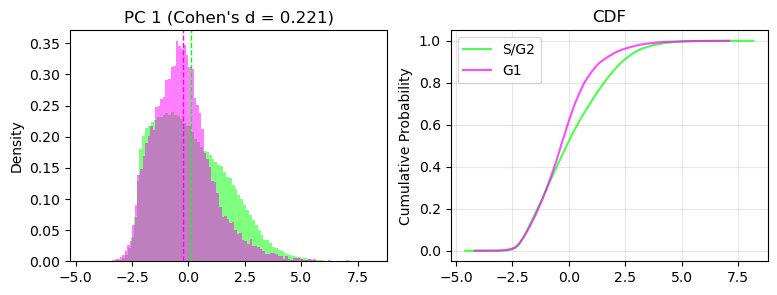

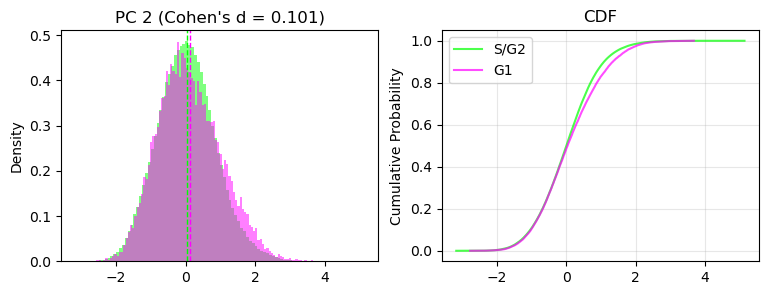

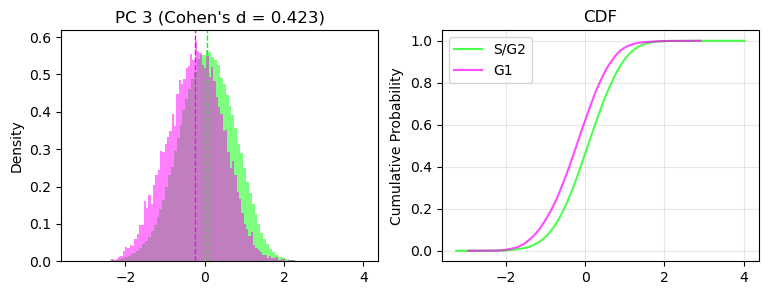

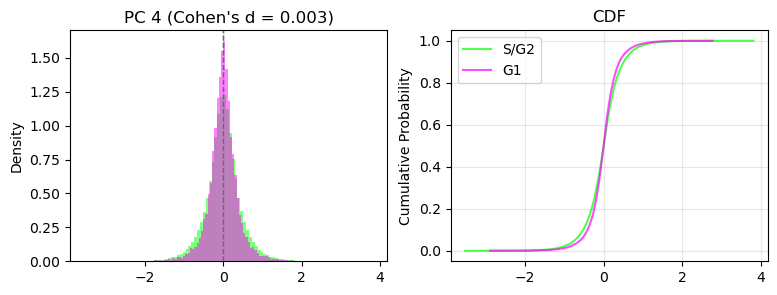

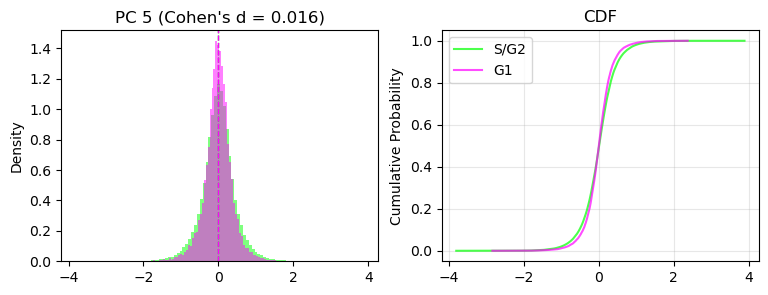

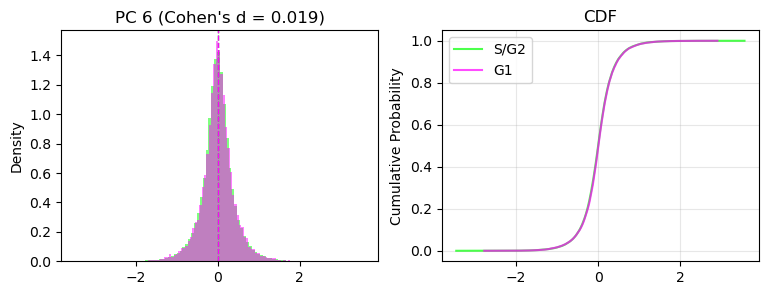

In [13]:
run_analysis(red_pca, green_pca, dir, is_somites=False)

$\LARGE{****************SOMITES****************}$

Somites
Left vs Right

In [29]:
query = pl.scan_csv(full_path)
outlier_ids = pl.read_csv(outlier_path)[ID_NAME].to_list()
query = (
    query
    .filter(~pl.col(ID_NAME).is_in(outlier_ids))
    .filter(pl.col('Somite_ID').is_not_null())
    .filter(pl.col('Somite_Side').is_not_null())
    .select(pl.col('Nuclear_ID', 'Somite_ID', 'Somite_Side'))
    .collect()
)
somites_LR = query.to_pandas()
ids_L = somites_LR[somites_LR['Somite_Side'] == 'Left']["Nuclear_ID"].to_list()
ids_R = somites_LR[somites_LR['Somite_Side'] == 'Right']["Nuclear_ID"].to_list()

pca_L = global_pca[global_pca.index.isin(ids_L)]
pca_R = global_pca[global_pca.index.isin(ids_R)]

print(len(pca_L)==len(ids_L))
print(len(pca_R)==len(ids_R))
print(len(pca_L) + len(pca_R) == len(somites_LR))

True
True
True


p-value: 0.013
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:01:08,903 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC1_somites_Left_Right.svg


p-value: 0.005
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:01:10,250 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC2_somites_Left_Right.svg


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:01:11,296 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC3_somites_Left_Right.svg


... (2 outputs left out)

p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:01:13,407 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC5_somites_Left_Right.svg


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:01:14,279 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC6_somites_Left_Right.svg


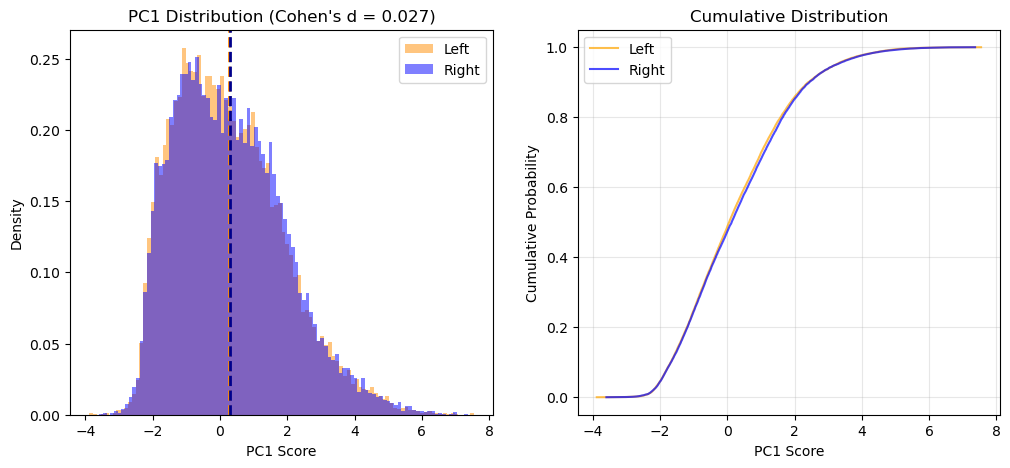

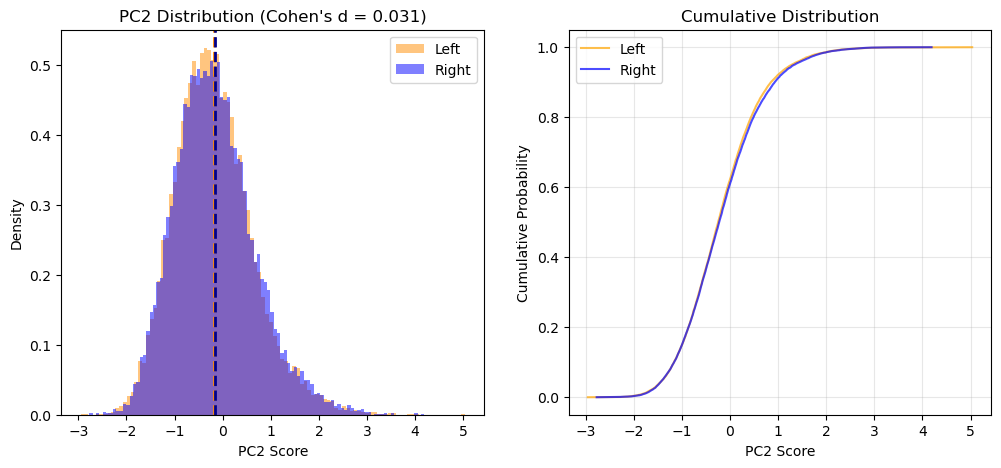

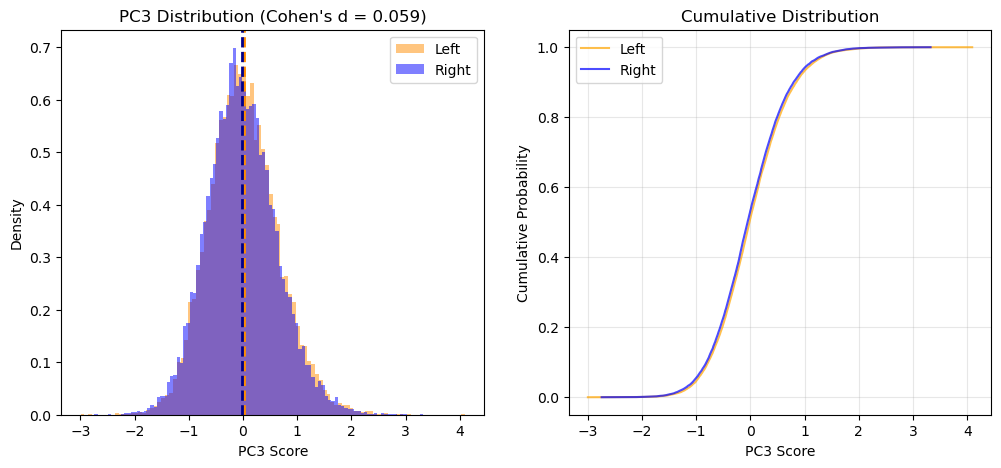

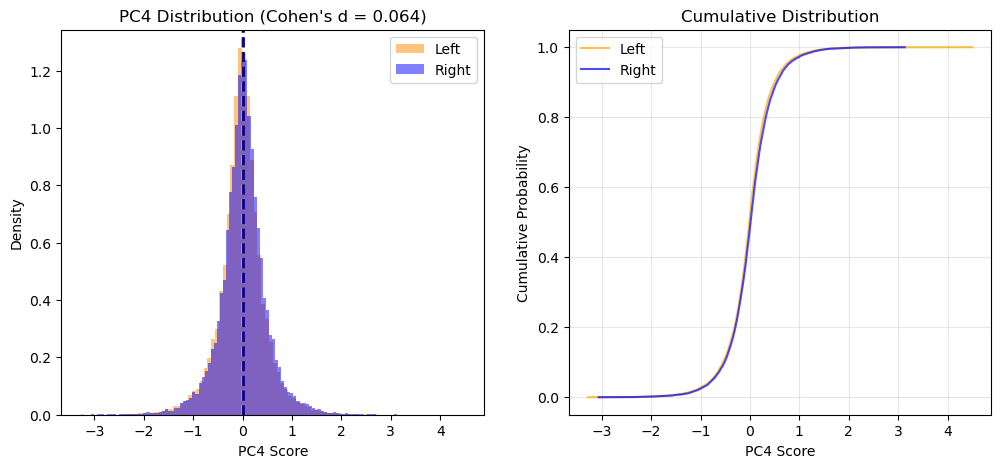

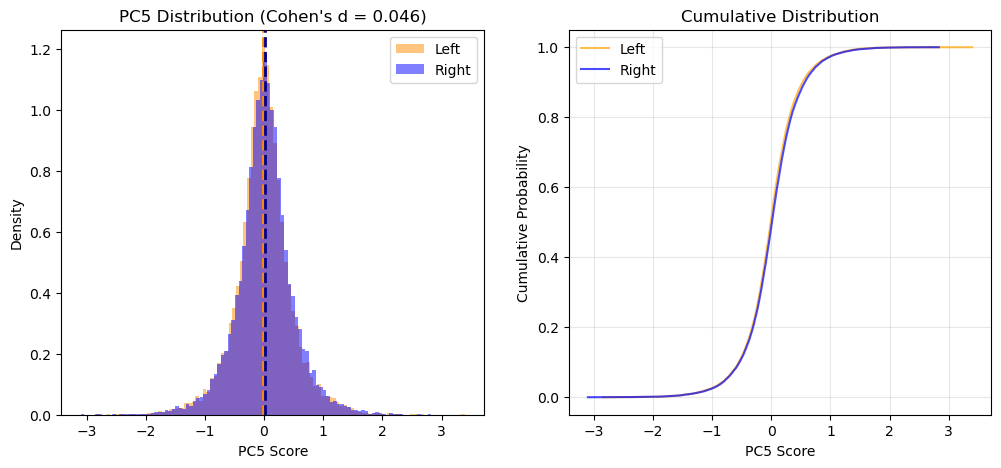

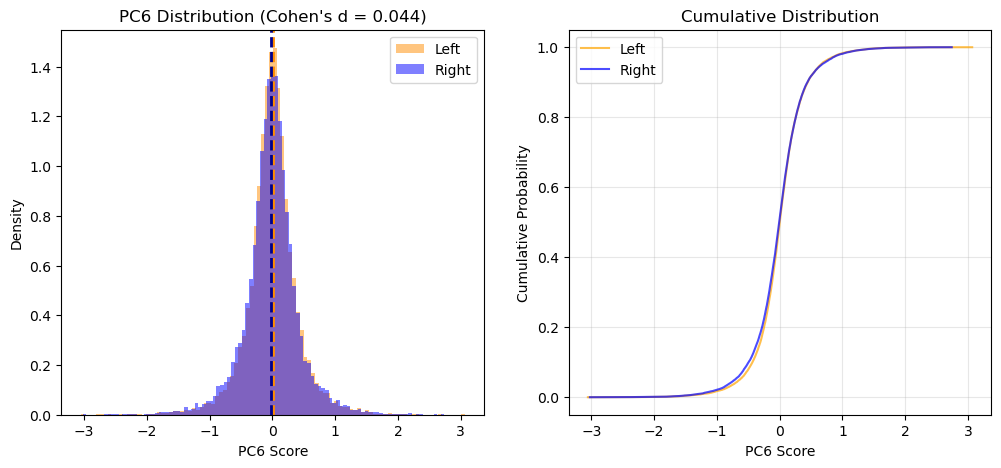

In [30]:
run_analysis_somites(pca_L, pca_R, dir,'Left', 'Right')

Somites by fucci class

In [31]:
query = pl.scan_csv(full_path)
outlier_ids = pl.read_csv(outlier_path)[ID_NAME].to_list()
query = (
    query
    .filter(~pl.col(ID_NAME).is_in(outlier_ids))
    .filter(pl.col("FUCCI_Class").is_in(["Green", "Red"]))
    .filter(pl.col('Somite_ID').is_not_null())
    .select(pl.col('Nuclear_ID', 'Somite_ID', "FUCCI_Class"))
    .collect()
)
somite_fucci_df = query.to_pandas()

In [32]:
red_somite_ids = somite_fucci_df[somite_fucci_df['FUCCI_Class'] == 'Red']["Nuclear_ID"].to_list()
green_somite_ids = somite_fucci_df[somite_fucci_df['FUCCI_Class'] == 'Green']["Nuclear_ID"].to_list()
red_somite_pca = global_pca[global_pca.index.isin(red_somite_ids)]
green_somite_pca = global_pca[global_pca.index.isin(green_somite_ids)]
print(len(red_somite_pca)==len(red_somite_ids))
print(len(green_somite_pca)==len(green_somite_ids))

True
True


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:01:45,159 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC1_distribution_somites.svg


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:01:45,753 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC2_distribution_somites.svg


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:01:46,367 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC3_distribution_somites.svg


... (2 outputs left out)

p-value: 0.470
Fail to reject null hypothesis: There is no significant difference between the two groups.


2025-11-10 12:01:47,506 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC5_distribution_somites.svg


p-value: 0.117
Fail to reject null hypothesis: There is no significant difference between the two groups.


2025-11-10 12:01:48,335 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC6_distribution_somites.svg


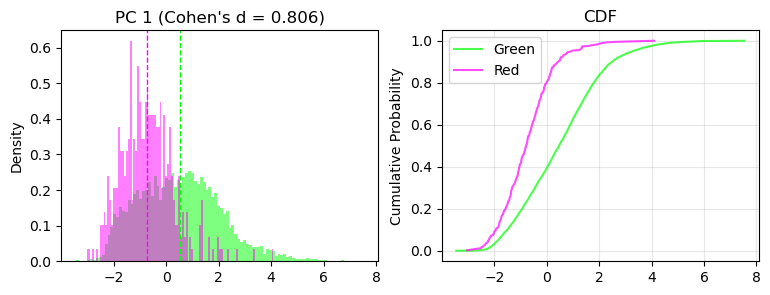

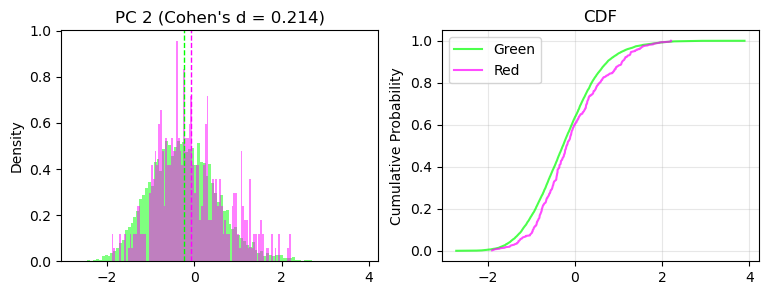

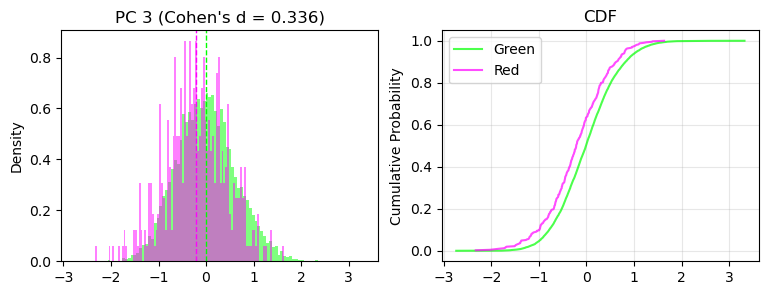

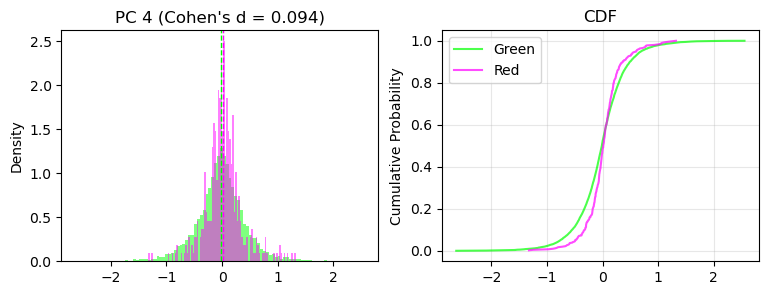

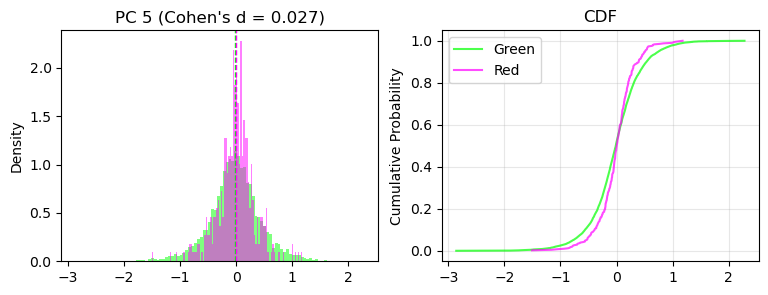

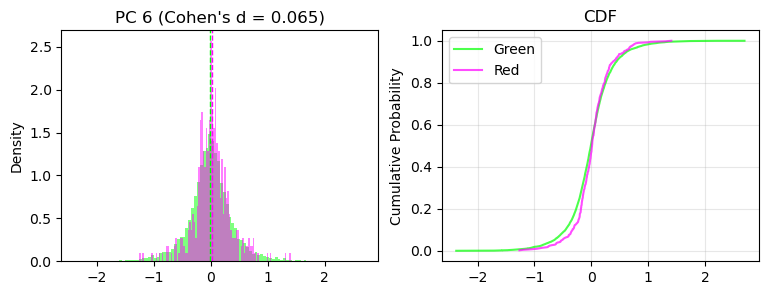

In [33]:
run_analysis(red_somite_pca, green_somite_pca, dir, is_somites=True)

$\large{STAGE}$

In [34]:
outlier_ids = pl.read_csv(outlier_path)[ID_NAME].to_list()
my_schema = {
    "Somite_Stage": pl.Float32,
}
query = pl.scan_csv(full_path, schema_overrides=my_schema)
query = (
    query
    .filter(~pl.col(ID_NAME).is_in(outlier_ids))
    .filter(pl.col('Somite_ID').is_not_null())
    .filter(pl.col('Somite_Stage').is_not_null())
    .select(pl.col('Nuclear_ID', 'Somite_ID', 'Somite_Stage'))
    .collect()
)

In [35]:
stages = query['Somite_Stage'].to_list()
max_stage = np.max(stages)
min_stage = np.min(stages)
halfway = (float(max_stage) + float(min_stage)) / 2
print(f"Max stage: {max_stage}, Min stage: {min_stage}, Halfway: {halfway}")

old_query = (
    query
    .filter(pl.col('Somite_Stage') <= halfway)
    .select(pl.col('Nuclear_ID'))
)
young_query = (
    query
    .filter(pl.col('Somite_Stage') > halfway)
    .select(pl.col('Nuclear_ID'))
)

Max stage: 21.0, Min stage: 1.0, Halfway: 11.0


In [36]:
young_ids = young_query["Nuclear_ID"].to_list()
old_ids = old_query["Nuclear_ID"].to_list()
print(len(young_ids), len(old_ids))
# green_somite_pca = global_pca[global_pca.index.isin(green_somite_ids)]
young_pca = global_pca[global_pca.index.isin(young_ids)]
old_pca = global_pca[global_pca.index.isin(old_ids)]
print(len(young_pca), len(old_pca))
print(young_pca.head())
print(old_pca.head())

17528 15567
17528 15567
            Nuclear_ID       PC1       PC2       PC3       PC4       PC5  \
Nuclear_ID                                                                 
89                  89  1.829775 -0.820679  0.886255  0.124092  1.542302   
91                  91  0.405283  0.698948  0.175222  0.169477 -0.262255   
99                  99 -0.639571  1.788510  0.414456  0.130660 -0.345517   
101                101 -1.731947 -0.265985 -0.384617  0.027043  0.358647   
102                102 -1.496444 -0.774973  0.084254  0.016298  0.029091   

                 PC6  
Nuclear_ID            
89         -0.309241  
91          0.001400  
99         -0.153774  
101         0.037304  
102         0.109151  
            Nuclear_ID       PC1       PC2       PC3       PC4       PC5  \
Nuclear_ID                                                                 
444373          444373 -0.667509 -0.542787  0.649339 -0.005356  0.295367   
444375          444375  1.559912  0.131714  1.217227 -

p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:02:21,740 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC1_somites_Young_Old.svg


p-value: 0.000
Reject null hypothesis: There is a significant difference between the two groups.


2025-11-10 12:02:22,460 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC2_somites_Young_Old.svg


p-value: 0.444
Fail to reject null hypothesis: There is no significant difference between the two groups.


2025-11-10 12:02:23,549 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC3_somites_Young_Old.svg


... (2 outputs left out)

p-value: 0.296
Fail to reject null hypothesis: There is no significant difference between the two groups.


2025-11-10 12:02:25,258 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC5_somites_Young_Old.svg


p-value: 0.310
Fail to reject null hypothesis: There is no significant difference between the two groups.


2025-11-10 12:02:25,956 - INFO - Saved plot: /net/beliveau/vol2/instrument/E9.5_306/Zoom_306/Shapemodes_Global_NewLabels/Conditional_Distributions/PC6_somites_Young_Old.svg


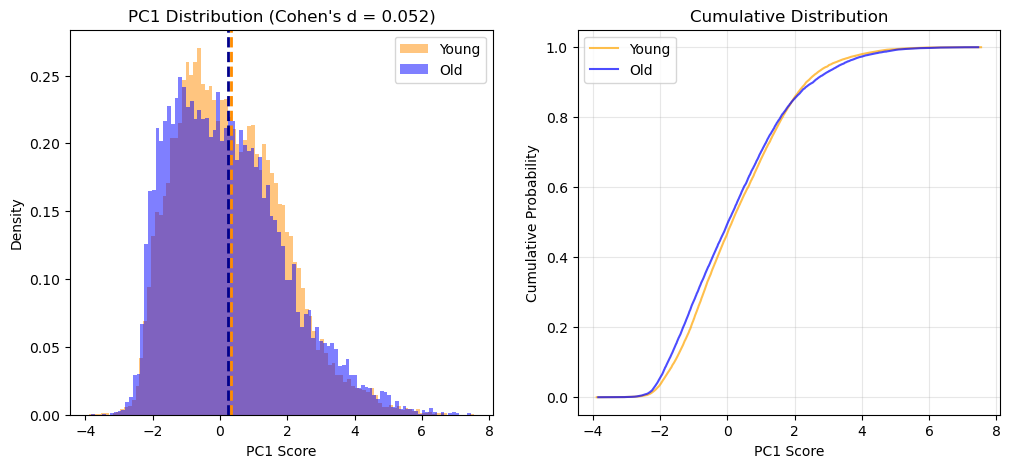

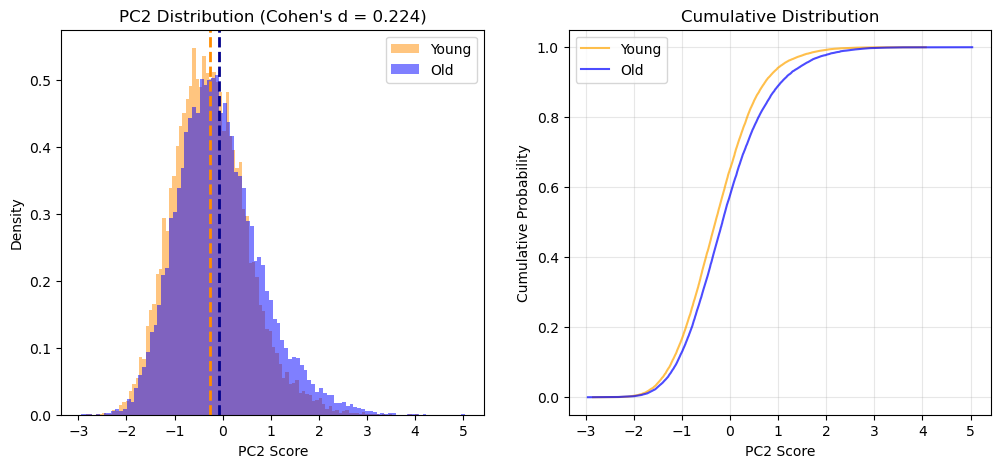

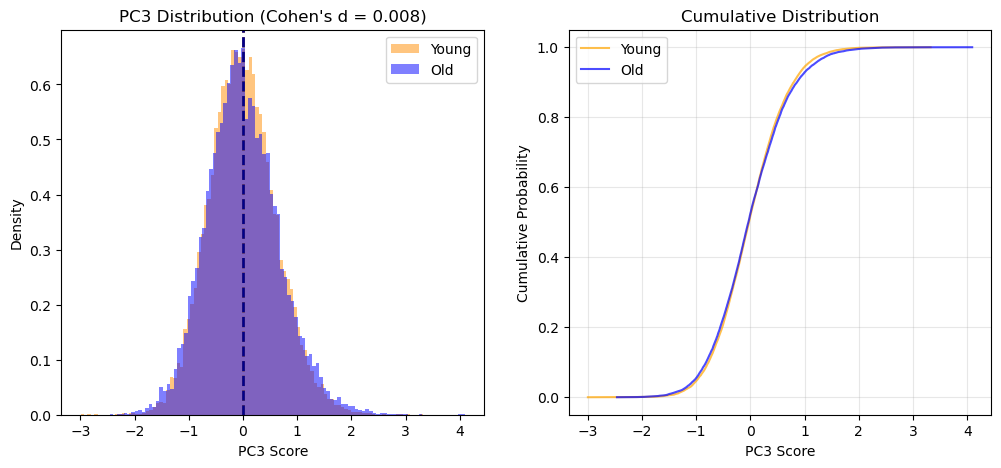

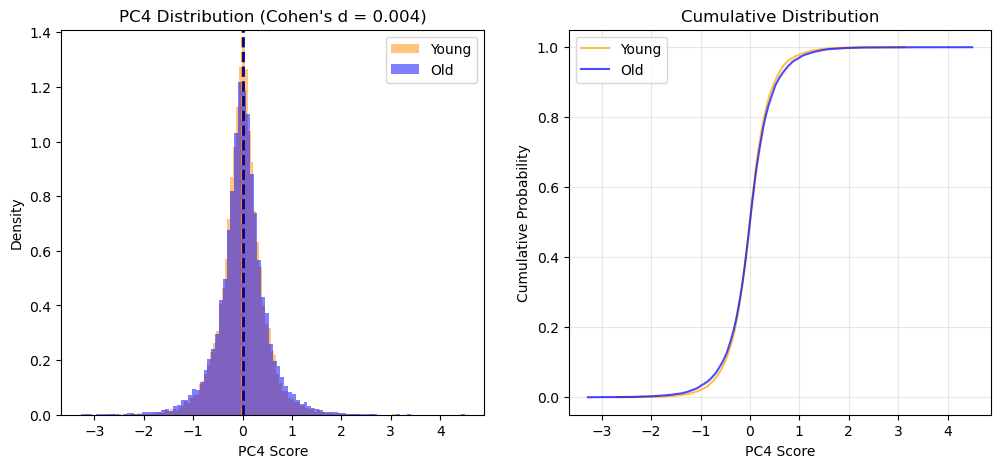

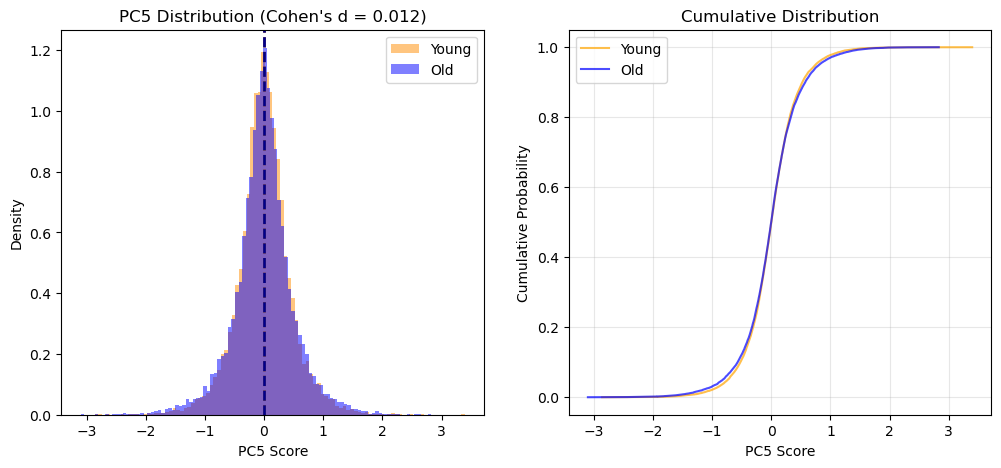

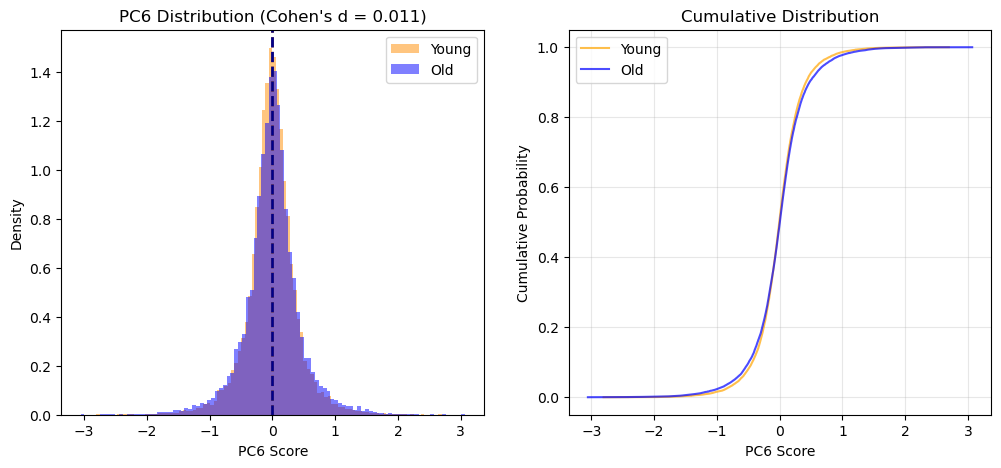

In [37]:
run_analysis_somites(young_pca, old_pca, dir, 'Young', 'Old')